# SATCAT catalogue breakdown

Reads the SATCAT file from the folder set in `config.ini` (section `[satcat]`, key `output_dir`),
then shows the breakdown of objects by category (`OBJECT_TYPE`) and by country (`COUNTRY`).

In [15]:
from pathlib import Path
import configparser
import pandas as pd
import matplotlib.pyplot as plt

# SATCAT folder read from config.ini (same file as spacetrack_satcat.py)
config = configparser.ConfigParser()
if not config.read("config.ini", encoding="utf-8"):
    raise FileNotFoundError("config.ini not found next to the notebook")
SATCAT_DIR  = Path(config["satcat"]["output_dir"]).expanduser()
SATCAT_FILE = SATCAT_DIR / "satcat_20261024.csv"

ON_ORBIT_ONLY = False   # True: keep only objects that have not decayed (empty DECAY)
TOP_N         = 15      # countries shown individually, the rest are grouped into "Others"

# Categories: display label and colour (fixed order)
TYPE_MAP = {
    "PAYLOAD":     ("Satellite",   "#2a78d6"),
    "DEBRIS":      ("Debris",      "#eb6834"),
    "ROCKET BODY": ("Upper Stage", "#1baf7a"),
    "UNKNOWN":     ("Unknown",     "#eda100"),
}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#3d3d3a",
    "xtick.color": "#3d3d3a", "ytick.color": "#3d3d3a",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "x", "grid.color": "#e8e7e1", "axes.axisbelow": True,
    "font.size": 11,
})

## Read the file

In [16]:
satcat = pd.read_csv(SATCAT_FILE)
print(f"File: {SATCAT_FILE}")
print(f"{len(satcat):,} objects in the catalogue, {satcat['DECAY'].notna().sum():,} of them decayed")

if ON_ORBIT_ONLY:
    satcat = satcat[satcat["DECAY"].isna()]
    print(f"On-orbit filter: {len(satcat):,} objects kept")

satcat["CATEGORY"] = satcat["OBJECT_TYPE"].map(lambda t: TYPE_MAP.get(t, (t,))[0])
satcat.head()

File: /Users/alexispetit/Documents/TLE_database/satcat/satcat_20261024.csv
71,125 objects in the catalogue, 35,726 of them decayed


,INTLDES,NORAD_CAT_ID,OBJECT_TYPE,SATNAME,COUNTRY,LAUNCH,SITE,DECAY,PERIOD,INCLINATION,...,RCS_SIZE,FILE,LAUNCH_YEAR,LAUNCH_NUM,LAUNCH_PIECE,CURRENT,OBJECT_NAME,OBJECT_ID,OBJECT_NUMBER,CATEGORY
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,...,LARGE,9552,1957,1,A,Y,SL-1 R/B,1957-001A,1,Upper Stage
1,1957-001B,2,PAYLOAD,SPUTNIK 1,CIS,1957-10-04,TTMTR,1958-01-03,96.10,65.00,...,NaN,9552,1957,1,B,Y,SPUTNIK 1,1957-001B,2,Satellite
2,1957-002A,3,PAYLOAD,SPUTNIK 2,CIS,1957-11-03,TTMTR,1958-04-14,103.74,65.33,...,NaN,9552,1957,2,A,Y,SPUTNIK 2,1957-002A,3,Satellite
3,1958-001A,4,PAYLOAD,EXPLORER 1,US,1958-02-01,AFETR,1970-03-31,88.48,33.15,...,NaN,9552,1958,1,A,Y,EXPLORER 1,1958-001A,4,Satellite
4,1958-002B,5,PAYLOAD,VANGUARD 1,US,1958-03-17,AFETR,NaN,132.59,34.25,...,MEDIUM,9627,1958,2,B,Y,VANGUARD 1,1958-002B,5,Satellite


## Breakdown by category

,Category,Objects,%
0,Satellite,27076,38.1
1,Debris,35932,50.5
2,Upper Stage,6919,9.7
3,Unknown,1198,1.7


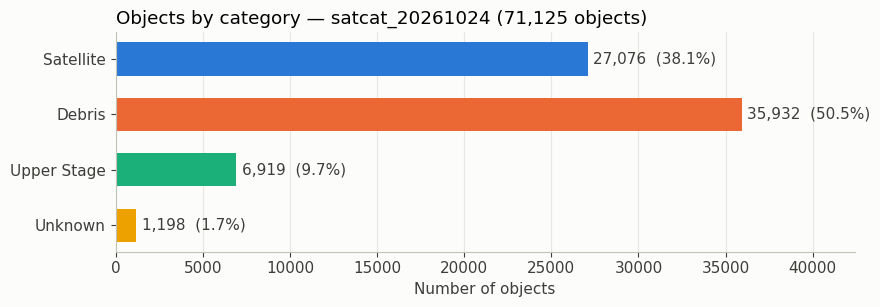

In [17]:
by_type = (satcat["OBJECT_TYPE"].value_counts()
           .reindex(TYPE_MAP).dropna().astype(int))
table_type = pd.DataFrame({
    "Category": [TYPE_MAP[t][0] for t in by_type.index],
    "Objects": by_type.values,
    "%": (100 * by_type / by_type.sum()).round(1).values,
})
display(table_type)

fig, ax = plt.subplots(figsize=(9, 3.2))
labels = [TYPE_MAP[t][0] for t in by_type.index]
colors = [TYPE_MAP[t][1] for t in by_type.index]
bars = ax.barh(labels, by_type.values, color=colors, height=0.6)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{v:,}  ({p}%)" for v, p in zip(by_type.values, table_type["%"])],
             padding=4, color="#3d3d3a")
ax.set_xlabel("Number of objects")
ax.set_title(f"Objects by category — {SATCAT_FILE.stem} ({by_type.sum():,} objects)", loc="left")
ax.margins(x=0.18)
fig.tight_layout()
plt.show()

## Breakdown by country

,Objects,%
US,29427,41.4
CIS,25239,35.5
PRC,9420,13.2
FR,1484,2.1
JPN,927,1.3
IND,767,1.1
UK,763,1.1
TBD,547,0.8
ESA,189,0.3
GER,155,0.2


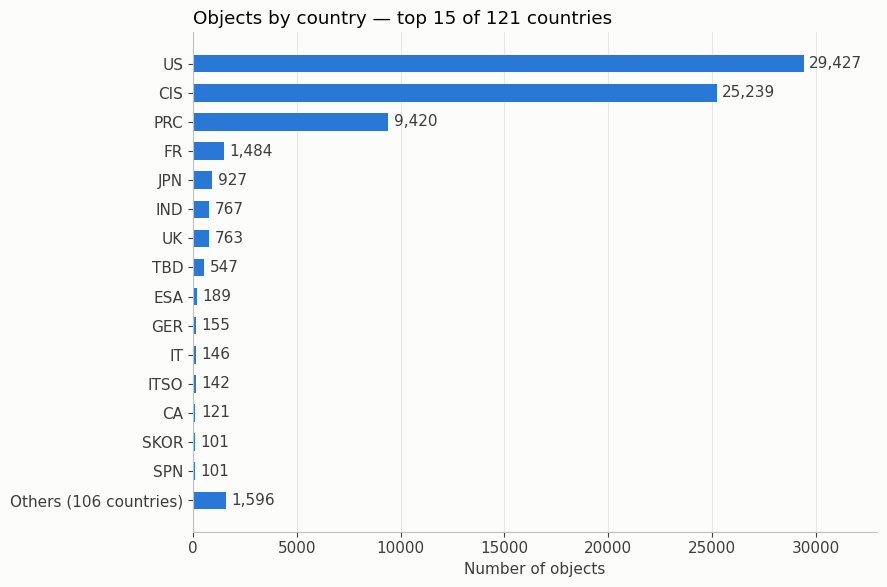

In [18]:
by_country = satcat["COUNTRY"].value_counts()
top = by_country.head(TOP_N)
others = by_country.iloc[TOP_N:]
top_others = pd.concat([top, pd.Series({f"Others ({len(others)} countries)": others.sum()})])

table_country = pd.DataFrame({
    "Objects": top_others,
    "%": (100 * top_others / top_others.sum()).round(1),
})
display(table_country)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top_others.index, top_others.values, color="#2a78d6", height=0.6)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{v:,}" for v in top_others.values], padding=4, color="#3d3d3a")
ax.set_xlabel("Number of objects")
ax.set_title(f"Objects by country — top {TOP_N} of {len(by_country)} countries", loc="left")
ax.margins(x=0.12)
fig.tight_layout()
plt.show()

## Breakdown by country and category

OBJECT_TYPE,Satellite,Debris,Upper Stage,Unknown,Total
COUNTRY,,,,,
US,18041,9693,1660,33,29427
CIS,3795,17392,4009,43,25239
PRC,1605,6603,690,522,9420
FR,162,1065,257,0,1484
JPN,367,399,141,20,927
IND,155,528,81,3,767
UK,758,4,1,0,763
TBD,5,0,0,542,547
ESA,134,42,12,1,189


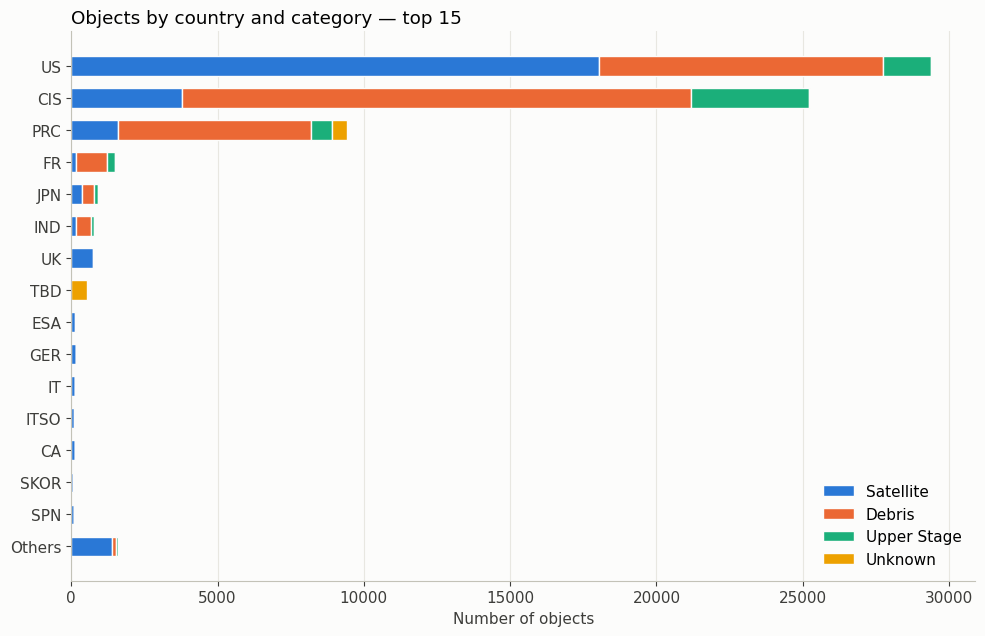

In [19]:
country_group = satcat["COUNTRY"].where(satcat["COUNTRY"].isin(top.index), "Others")
cross = (pd.crosstab(country_group, satcat["OBJECT_TYPE"])
         .reindex(columns=[t for t in TYPE_MAP if t in satcat["OBJECT_TYPE"].unique()], fill_value=0)
         .reindex(list(top.index) + ["Others"]))
display(cross.rename(columns={t: TYPE_MAP[t][0] for t in TYPE_MAP}).assign(Total=cross.sum(axis=1)))

fig, ax = plt.subplots(figsize=(10, 6.5))
left = pd.Series(0, index=cross.index)
for obj_type in cross.columns:
    label, color = TYPE_MAP[obj_type]
    ax.barh(cross.index, cross[obj_type], left=left, color=color, height=0.6,
            edgecolor="#fcfcfb", linewidth=1, label=label)
    left += cross[obj_type]
ax.invert_yaxis()
ax.set_xlabel("Number of objects")
ax.set_title(f"Objects by country and category — top {TOP_N}", loc="left")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

## Recently catalogued objects

Objects launched during the last `RECENT_DAYS` days, counted back from the most recent launch date in the file.
NORAD IDs are assigned in cataloguing order, so the highest IDs are the latest entries.

In [20]:
RECENT_DAYS = 90        # analysis window, in days before the most recent launch in the file
LAST_N      = 20        # number of latest entries listed

satcat["LAUNCH"] = pd.to_datetime(satcat["LAUNCH"], errors="coerce")
ref_date = satcat["LAUNCH"].max()
start    = ref_date - pd.Timedelta(days=RECENT_DAYS)
recent   = satcat[satcat["LAUNCH"] > start]
print(f"Window: {start:%Y-%m-%d} → {ref_date:%Y-%m-%d} ({RECENT_DAYS} days)")
print(f"{len(recent):,} objects launched in the window")

print(f"\nLast {LAST_N} catalogue entries:")
display(satcat.nlargest(LAST_N, "NORAD_CAT_ID")
        [["NORAD_CAT_ID", "OBJECT_NAME", "OBJECT_ID", "CATEGORY", "COUNTRY", "LAUNCH", "SITE"]]
        .reset_index(drop=True))

Window: 2026-07-23 → 2026-10-21 (90 days)
866 objects launched in the window

Last 20 catalogue entries:


,NORAD_CAT_ID,OBJECT_NAME,OBJECT_ID,CATEGORY,COUNTRY,LAUNCH,SITE
0,101143,FLOCK 4J 9,2026-227CX,Satellite,US,2026-10-01,AFWTR
1,101142,XIGUANG-4 01,2026-238A,Satellite,PRC,2026-10-21,YSLA
2,101141,OBJECT AG,2026-237AG,Unknown,TBD,2026-10-20,AFETR
3,101140,OBJECT AF,2026-237AF,Unknown,TBD,2026-10-20,AFETR
4,101139,OBJECT AE,2026-237AE,Unknown,TBD,2026-10-20,AFETR
5,101138,OBJECT AD,2026-237AD,Unknown,TBD,2026-10-20,AFETR
6,101137,OBJECT AC,2026-237AC,Unknown,TBD,2026-10-20,AFETR
7,101136,OBJECT AB,2026-237AB,Unknown,TBD,2026-10-20,AFETR
8,101135,OBJECT AA,2026-237AA,Unknown,TBD,2026-10-20,AFETR
9,101134,OBJECT Z,2026-237Z,Unknown,TBD,2026-10-20,AFETR


### Objects launched in the last `LIST_DAYS` days

SATCAT has no cataloguing date, so the launch date is used instead.
First a summary per launch (international designator `OBJECT_ID` without the piece letters), then the full list.

In [21]:
LIST_DAYS = 20          # list window, in days before the most recent launch in the file

latest = (satcat[satcat["LAUNCH"] > ref_date - pd.Timedelta(days=LIST_DAYS)]
          .sort_values(["LAUNCH", "NORAD_CAT_ID"], ascending=False))
print(f"{len(latest):,} objects launched between "
      f"{ref_date - pd.Timedelta(days=LIST_DAYS):%Y-%m-%d} and {ref_date:%Y-%m-%d}")

launches = (latest.assign(LAUNCH_ID=latest["OBJECT_ID"].str.extract(r"^(\d{4}-\d{3})", expand=False))
            .groupby("LAUNCH_ID")
            .agg(Launch=("LAUNCH", "first"),
                 Site=("SITE", "first"),
                 Country=("COUNTRY", lambda s: ", ".join(s.value_counts().index)),
                 Objects=("NORAD_CAT_ID", "size"),
                 Example=("OBJECT_NAME", "first"),
                 **{TYPE_MAP[t][0]: ("OBJECT_TYPE", lambda s, t=t: (s == t).sum()) for t in TYPE_MAP})
            .sort_values(["Launch", "LAUNCH_ID"], ascending=False))
display(launches)

120 objects launched between 2026-10-01 and 2026-10-21


,Launch,Site,Country,Objects,Example,Satellite,Debris,Upper Stage,Unknown
LAUNCH_ID,,,,,,,,,
2026-238,2026-10-21,YSLA,PRC,1,XIGUANG-4 01,1,0,0,0
2026-237,2026-10-20,AFETR,TBD,31,OBJECT AG,0,0,0,31
2026-236,2026-10-19,TNSTA,JPN,2,H-3 R/B,1,0,1,0
2026-234,2026-10-14,JSC,PRC,11,ZQ-2E R/B,0,0,1,10
2026-233,2026-10-13,AFETR,US,1,DRAGON CRS-35,1,0,0,0
2026-232,2026-10-13,AFWTR,US,27,STARLINK-38472,27,0,0,0
2026-231,2026-10-10,AFWTR,US,21,SDA-NG-T1TL-421,21,0,0,0
2026-230,2026-10-09,WSC,PRC,10,CZ-12 R/B,9,0,1,0
2026-229,2026-10-07,NSC,SKOR,15,KSLV-II R/B,6,0,1,8


In [22]:
with pd.option_context("display.max_rows", None):
    display(latest[["NORAD_CAT_ID", "OBJECT_NAME", "OBJECT_ID", "CATEGORY", "COUNTRY",
                    "LAUNCH", "SITE", "RCS_SIZE", "DECAY"]]
            .reset_index(drop=True))

,NORAD_CAT_ID,OBJECT_NAME,OBJECT_ID,CATEGORY,COUNTRY,LAUNCH,SITE,RCS_SIZE,DECAY
0,101142,XIGUANG-4 01,2026-238A,Satellite,PRC,2026-10-21,YSLA,NaN,NaN
1,101141,OBJECT AG,2026-237AG,Unknown,TBD,2026-10-20,AFETR,NaN,NaN
2,101140,OBJECT AF,2026-237AF,Unknown,TBD,2026-10-20,AFETR,NaN,NaN
3,101139,OBJECT AE,2026-237AE,Unknown,TBD,2026-10-20,AFETR,NaN,NaN
4,101138,OBJECT AD,2026-237AD,Unknown,TBD,2026-10-20,AFETR,NaN,NaN
5,101137,OBJECT AC,2026-237AC,Unknown,TBD,2026-10-20,AFETR,NaN,NaN
6,101136,OBJECT AB,2026-237AB,Unknown,TBD,2026-10-20,AFETR,NaN,NaN
7,101135,OBJECT AA,2026-237AA,Unknown,TBD,2026-10-20,AFETR,NaN,NaN
8,101134,OBJECT Z,2026-237Z,Unknown,TBD,2026-10-20,AFETR,NaN,NaN
9,101133,OBJECT Y,2026-237Y,Unknown,TBD,2026-10-20,AFETR,NaN,NaN


OBJECT_TYPE,Satellite,Debris,Upper Stage,Unknown,Total
COUNTRY,,,,,
US,576,0,13,0,589
PRC,69,4,14,49,136
TBD,0,0,0,67,67
SKOR,8,0,1,8,17
JPN,7,0,2,0,9
SPN,6,0,0,0,6
CIS,2,0,3,1,6
ESA,3,1,1,0,5
IT,4,0,0,0,4


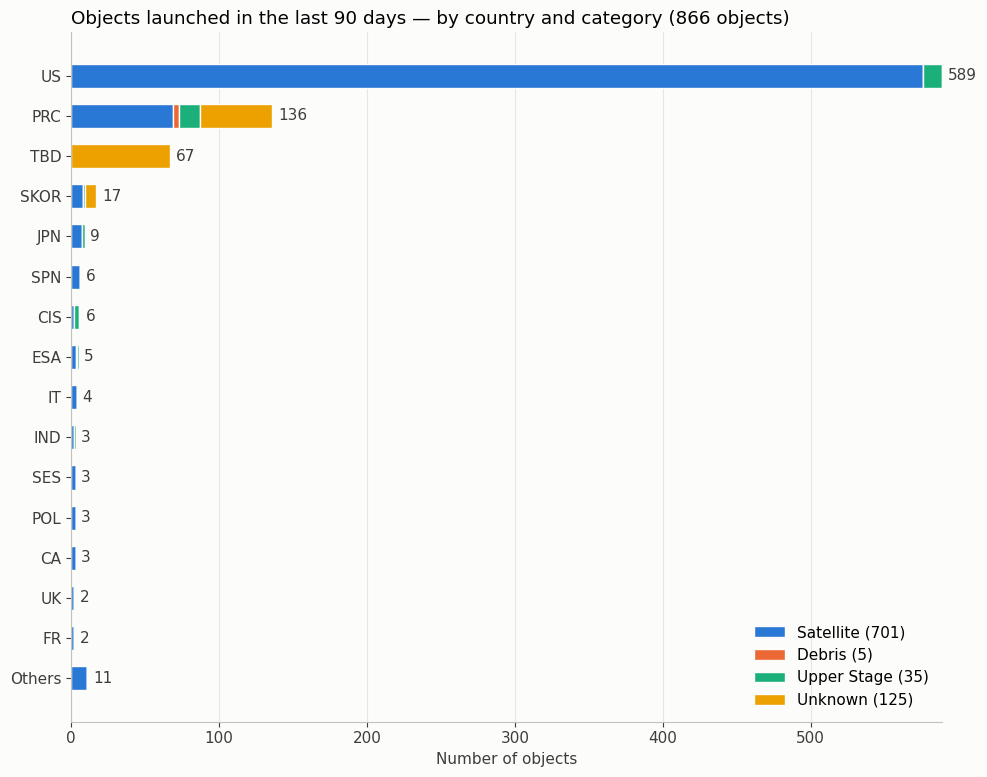

In [23]:
recent_top = recent["COUNTRY"].value_counts().head(TOP_N).index
recent_country = recent["COUNTRY"].where(recent["COUNTRY"].isin(recent_top), "Others")
recent_cross = pd.crosstab(recent_country, recent["OBJECT_TYPE"])
recent_cross = recent_cross.reindex(columns=[t for t in TYPE_MAP if t in recent_cross.columns],
                                    index=[c for c in [*recent_top, "Others"] if c in recent_cross.index])
display(recent_cross.rename(columns={t: TYPE_MAP[t][0] for t in TYPE_MAP})
        .assign(Total=recent_cross.sum(axis=1)))

fig, ax = plt.subplots(figsize=(10, 0.4 * len(recent_cross) + 1.5))
left = pd.Series(0, index=recent_cross.index)
for obj_type in recent_cross.columns:
    label, color = TYPE_MAP[obj_type]
    ax.barh(recent_cross.index, recent_cross[obj_type], left=left, color=color, height=0.6,
            edgecolor="#fcfcfb", linewidth=1, label=f"{label} ({recent_cross[obj_type].sum():,})")
    left += recent_cross[obj_type]
ax.bar_label(ax.containers[-1], labels=[f"{v:,}" for v in left], padding=4, color="#3d3d3a")
ax.invert_yaxis()
ax.set_xlabel("Number of objects")
ax.set_title(f"Objects launched in the last {RECENT_DAYS} days — by country and category "
             f"({len(recent):,} objects)", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.margins(x=0.08)
fig.tight_layout()
plt.show()

### Programmes in the window

Grouped by the first word of `OBJECT_NAME`, without long serial numbers (`STARLINK-38298` → `STARLINK`).
`OBJECT` means the piece is not identified yet (names like `OBJECT A`, `OBJECT B`…).

In [24]:
programme = recent["OBJECT_NAME"].str.split().str[0].str.replace(r"-\d{3,}$", "", regex=True)
by_programme = (recent.assign(PROGRAMME=programme)
                .groupby("PROGRAMME")
                .agg(Objects=("NORAD_CAT_ID", "size"),
                     Country=("COUNTRY", lambda s: ", ".join(s.value_counts().index[:3])),
                     First_launch=("LAUNCH", "min"),
                     Last_launch=("LAUNCH", "max"))
                .sort_values("Objects", ascending=False))
display(by_programme.head(20))

,Objects,Country,First_launch,Last_launch
PROGRAMME,,,,
STARLINK,419,US,2026-07-25,2026-10-13
OBJECT,125,"TBD, PRC, SKOR",2026-08-05,2026-10-20
USA,88,US,2026-07-30,2026-10-02
HULIANWANG,45,PRC,2026-08-04,2026-10-09
SDA-NG-T1TL,21,US,2026-10-10,2026-10-10
ELECTRON,12,US,2026-08-06,2026-09-26
FLOCK,11,US,2026-10-01,2026-10-01
QIANFAN,10,PRC,2026-09-15,2026-09-15
GLOBALSTAR,8,US,2026-08-16,2026-08-16


## New objects per launch month (last 12 months, current month included)

OBJECT_TYPE,Satellite,Debris,Upper Stage,Unknown,Total
LAUNCH,,,,,
2025-11,453,1,16,27,497
2025-12,425,0,23,60,508
2026-01,325,3,8,4,340
2026-02,341,8,5,9,363
2026-03,497,72,15,12,596
2026-04,381,3,12,16,412
2026-05,355,0,8,6,369
2026-06,361,7,14,19,401
2026-07,397,2,11,26,436


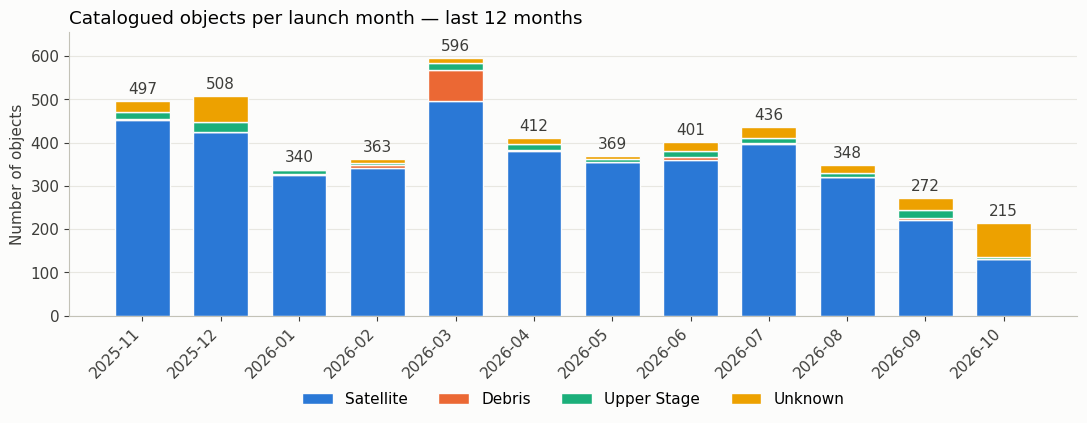

The latest months are incomplete: objects keep being catalogued for weeks after launch.


In [25]:
first_month = ref_date.to_period("M") - 11
last_year = satcat[satcat["LAUNCH"].dt.to_period("M") >= first_month]
monthly = (pd.crosstab(last_year["LAUNCH"].dt.to_period("M"), last_year["OBJECT_TYPE"])
           .reindex(columns=[t for t in TYPE_MAP if t in last_year["OBJECT_TYPE"].unique()], fill_value=0))
display(monthly.rename(columns={t: TYPE_MAP[t][0] for t in TYPE_MAP}).assign(Total=monthly.sum(axis=1)))

fig, ax = plt.subplots(figsize=(11, 4.5))
x = monthly.index.strftime("%Y-%m")
bottom = pd.Series(0, index=monthly.index)
for obj_type in monthly.columns:
    label, color = TYPE_MAP[obj_type]
    ax.bar(x, monthly[obj_type], bottom=bottom, color=color, width=0.7,
           edgecolor="#fcfcfb", linewidth=1, label=label)
    bottom += monthly[obj_type]
ax.bar_label(ax.containers[-1], labels=[f"{v:,}" for v in bottom], padding=3, color="#3d3d3a")
ax.grid(axis="x", visible=False)
ax.grid(axis="y", visible=True)
ax.set_ylabel("Number of objects")
ax.set_title("Catalogued objects per launch month — last 12 months", loc="left")
ax.legend(frameon=False, ncols=len(monthly.columns), loc="upper center", bbox_to_anchor=(0.5, -0.22))
ax.margins(y=0.1)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
plt.show()
print("The latest months are incomplete: objects keep being catalogued for weeks after launch.")